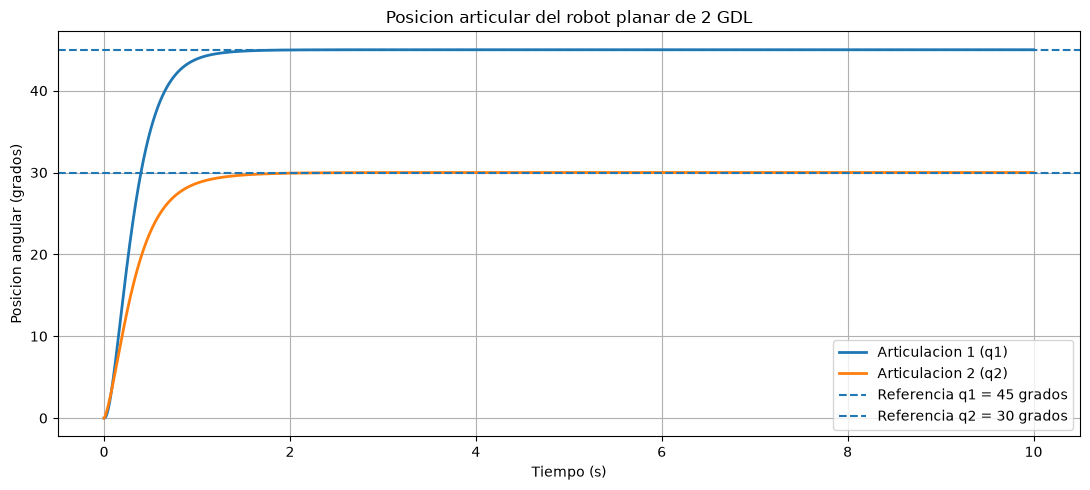

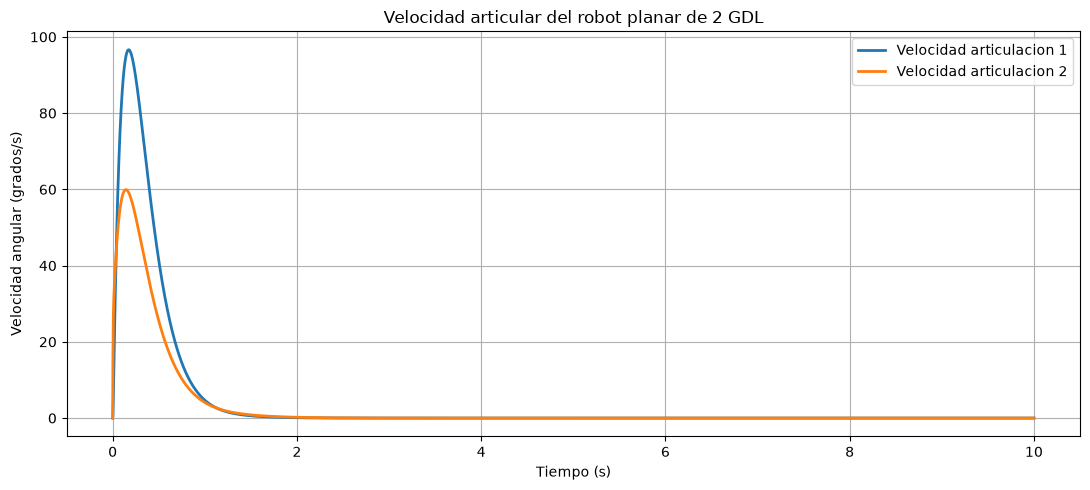


RESULTADOS DE LA SIMULACION
Tiempo de simulacion: 10 segundos
Posicion final q1: 45.00 grados
Posicion final q2: 30.00 grados
Velocidad final q1: -0.00 grados/s
Velocidad final q2: 0.00 grados/s

Simulacion finalizada correctamente


In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ==========================================
# PROYECTO FINAL - MODELADO Y SIMULACION
# Robot manipulador planar de 2 GDL
# Modelo dinamico mediante Euler-Lagrange
# ==========================================

# PARAMETROS FISICOS DEL ROBOT
# Valores de ejemplo para la simulacion

m1 = 2.0
m2 = 1.5

l1 = 0.5
l2 = 0.4

lc1 = 0.25
lc2 = 0.20

I1 = 0.04
I2 = 0.02

g = 9.81

# COEFICIENTES DE FRICCION
b1 = 0.15
b2 = 0.10

fc1 = 0.08
fc2 = 0.05

# POSICIONES DESEADAS
q1_deseada = np.radians(45)
q2_deseada = np.radians(30)

# GANANCIAS DEL CONTROLADOR PD
kp1 = 35.0
kp2 = 20.0

kd1 = 12.0
kd2 = 7.0


# ==========================================
# FUNCION DEL MODELO DINAMICO
# ==========================================

def dinamica_robot(t, estado):

    q1, q2, dq1, dq2 = estado

    # MATRIZ DE INERCIA M(q)

    M11 = (
        m1 * lc1**2 + I1
        + m2 * (
            l1**2 + lc2**2
            + 2 * l1 * lc2 * np.cos(q2)
        ) + I2
    )

    M12 = (
        m2 * (
            lc2**2
            + l1 * lc2 * np.cos(q2)
        ) + I2
    )

    M21 = M12

    M22 = m2 * lc2**2 + I2

    M = np.array([
        [M11, M12],
        [M21, M22]
    ])

    # MATRIZ DE CORIOLIS Y CENTRIFUGA

    c1 = m2 * l1 * lc2 * np.sin(q2)

    C = np.array([
        [-c1 * dq2, -c1 * (dq1 + dq2)],
        [c1 * dq1, 0]
    ])

    velocidades = np.array([dq1, dq2])

    coriolis = C @ velocidades

    # VECTOR DE GRAVEDAD G(q)

    G1 = (
        (m1 * lc1 + m2 * l1)
        * g * np.cos(q1)
        + m2 * g * lc2 * np.cos(q1 + q2)
    )

    G2 = (
        m2 * g * lc2
        * np.cos(q1 + q2)
    )

    G = np.array([G1, G2])

    # VECTOR DE FRICCION
    # Friccion de Coulomb suavizada

    F1 = (
        b1 * dq1
        + fc1 * np.tanh(dq1 / 0.05)
    )

    F2 = (
        b2 * dq2
        + fc2 * np.tanh(dq2 / 0.05)
    )

    F = np.array([F1, F2])

    # CONTROLADOR PD

    error1 = q1_deseada - q1
    error2 = q2_deseada - q2

    torque1 = (
        kp1 * error1
        - kd1 * dq1
        + G1
    )

    torque2 = (
        kp2 * error2
        - kd2 * dq2
        + G2
    )

    tau = np.array([torque1, torque2])

    # ECUACION DINAMICA
    # M(q)*ddq = tau - C*dq - G - F

    aceleraciones = np.linalg.solve(
        M,
        tau - coriolis - G - F
    )

    return [
        dq1,
        dq2,
        aceleraciones[0],
        aceleraciones[1]
    ]


# ==========================================
# SIMULACION DURANTE 10 SEGUNDOS
# ==========================================

tiempo = np.linspace(0, 10, 4001)

# Condiciones iniciales
# q1, q2, dq1, dq2

estado_inicial = [0, 0, 0, 0]

resultado = solve_ivp(
    dinamica_robot,
    (0, 10),
    estado_inicial,
    t_eval=tiempo,
    method="RK45",
    rtol=1e-6,
    atol=1e-8
)

if not resultado.success:
    raise RuntimeError(resultado.message)

# CONVERSION A GRADOS

q1 = np.degrees(resultado.y[0])
q2 = np.degrees(resultado.y[1])

dq1 = np.degrees(resultado.y[2])
dq2 = np.degrees(resultado.y[3])


# ==========================================
# GRAFICA DE POSICION ARTICULAR
# ==========================================

plt.figure(figsize=(11, 5))

plt.plot(
    resultado.t,
    q1,
    label="Articulacion 1 (q1)",
    linewidth=2
)

plt.plot(
    resultado.t,
    q2,
    label="Articulacion 2 (q2)",
    linewidth=2
)

plt.axhline(
    y=45,
    linestyle="--",
    label="Referencia q1 = 45 grados"
)

plt.axhline(
    y=30,
    linestyle="--",
    label="Referencia q2 = 30 grados"
)

plt.title(
    "Posicion articular del robot planar de 2 GDL"
)

plt.xlabel("Tiempo (s)")
plt.ylabel("Posicion angular (grados)")

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "posicion_articular.png",
    dpi=200
)

plt.show()


# ==========================================
# GRAFICA DE VELOCIDAD ARTICULAR
# ==========================================

plt.figure(figsize=(11, 5))

plt.plot(
    resultado.t,
    dq1,
    label="Velocidad articulacion 1",
    linewidth=2
)

plt.plot(
    resultado.t,
    dq2,
    label="Velocidad articulacion 2",
    linewidth=2
)

plt.title(
    "Velocidad articular del robot planar de 2 GDL"
)

plt.xlabel("Tiempo (s)")
plt.ylabel("Velocidad angular (grados/s)")

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "velocidad_articular.png",
    dpi=200
)

plt.show()


# ==========================================
# RESULTADOS FINALES
# ==========================================

print("\n================================")
print("RESULTADOS DE LA SIMULACION")
print("================================")

print("Tiempo de simulacion: 10 segundos")

print(
    f"Posicion final q1: {q1[-1]:.2f} grados"
)

print(
    f"Posicion final q2: {q2[-1]:.2f} grados"
)

print(
    f"Velocidad final q1: {dq1[-1]:.2f} grados/s"
)

print(
    f"Velocidad final q2: {dq2[-1]:.2f} grados/s"
)

print("\nSimulacion finalizada correctamente")
